# 05 · Validação fora do tempo

O modelo foi ajustado nas safras de 2007 a 2015. Aqui ele é avaliado nas safras de **2016 a 2018**, que ele nunca viu, como aconteceria em produção: o modelo é treinado com o passado e aplicado aos contratos novos.

**Do HR à probabilidade.** O notebook 04 estimou *efeitos*. Para provisionar, é preciso a **probabilidade de default até o mês *t*** de cada contrato, e ela depende também do pré-pagamento: quem quita sai do risco. Por isso a previsão usa **dois Cox específicos por causa**, um para default e outro para pré-pagamento, combinados pela recursão do Aalen-Johansen (`time_to_default.predict`). O prazo vira **estrato**, com uma curva basal própria para 36 e 60 meses, porque o pré-pagamento muda muito com o prazo.

**Dois candidatos:**
- **modelo único:** um Cox por causa, com coeficientes constantes no tempo;
- **modelo por fase:** um Cox por causa e por fase do contrato (1–6, 7–12, 13–24, 25–36 e 37–60 meses), que deixa os efeitos mudarem ao longo do tempo, como o notebook 04 mostrou que acontece.

**Métricas:**
- **ordenação:** C-index de Harrell no default (o pré-pagamento é censura);
- **calibração:** PD média prevista contra a incidência acumulada observada (Aalen-Johansen), por safra e por decil de risco.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines.utils import concordance_index

from time_to_default.cox import PERIODS, TRAIN_VINTAGES, design_matrix
from time_to_default.features import PROCESSED_PATH
from time_to_default.plotting import BLUE, GRAY, LIGHT_GRAY, ORANGE, percent_axis, savefig, set_style
from time_to_default.predict import CompetingRisksCox, fit_default_scale
from time_to_default.reporting import update_metrics
from time_to_default.survival import life_table

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

data = pd.read_parquet(PROCESSED_PATH)
train = design_matrix(data[data["vintage"].isin(TRAIN_VINTAGES)])
test_rows = data[data["vintage"] >= 2016]
test = design_matrix(test_rows)
test[["vintage", "event", "grade"]] = test_rows.loc[test.index, ["vintage", "event", "grade"]]
del data
print(f"treino: {len(train):,} contratos (safras 2007–2015) | teste: {len(test):,} (safras 2016–2018)")

treino: 883,528 contratos (safras 2007–2015) | teste: 1,179,731 (safras 2016–2018)


In [2]:
models = {
    "modelo único": CompetingRisksCox().fit(train),
    "modelo por fase": CompetingRisksCox(periods=PERIODS).fit(train),
}
preds = {name: m.cumulative_default(test) for name, m in models.items()}

## 1. Conferência no treino

Antes de olhar o teste, a PD média prevista no próprio treino precisa bater com o Aalen-Johansen. Se não bater, o problema é de mecânica do modelo, e não de mudança entre safras.

In [3]:
train_event = np.select([train["default"] == 1, train["prepay"] == 1], [1, 2], 0)
rows = []
for name, m in models.items():
    p = m.cumulative_default(train)
    for term_60, months in [(0, 36), (1, 60)]:
        r = (train["term_60"] == term_60).to_numpy()
        tab = life_table(train["duration"][r], train_event[r])
        rows.append({"modelo": name, "prazo": months,
                     "PD 12m prevista": p["pd_12m"][r].mean(), "PD 12m observada": tab.loc[12, "cif_default"],
                     "PD no prazo prevista": p["pd_lifetime"][r].mean(), "PD no prazo observada": tab.loc[months, "cif_default"]})
pd.DataFrame(rows).set_index(["modelo", "prazo"])

PD 12m prevista  PD 12m observada  \
modelo          prazo                                      
modelo único    36              0.0431            0.0433   
                60              0.0642            0.0644   
modelo por fase 36              0.0428            0.0433   
                60              0.0637            0.0644   

                       PD no prazo prevista  PD no prazo observada  
modelo          prazo                                               
modelo único    36                   0.1376                 0.1389  
                60                   0.2635                 0.2691  
modelo por fase 36                   0.1372                 0.1389  
                60                   0.2643                 0.2691

## 2. Ordenação (C-index) fora do tempo

Como referência, entra também o **grade da própria LendingClub** usado como score (A = 1 … G = 7). Ele é o benchmark natural, porque resume a análise de crédito da plataforma no momento da concessão.

In [4]:
grade_score = test["grade"].map({g: i for i, g in enumerate("ABCDEFG", start=1)}).astype(float)
c_index = pd.Series({
    "grade da LendingClub": concordance_index(test["duration"], -grade_score, test["default"]),
    **{name: concordance_index(test["duration"], -p["pd_12m"], test["default"]) for name, p in preds.items()},
}, name="C-index (teste)")
c_index.to_frame()

,C-index (teste)
grade da LendingClub,0.6820
modelo único,0.6975
modelo por fase,0.6994


## 3. Calibração por safra

A incidência observada vem do Aalen-Johansen de cada grupo, que respeita a censura e o pré-pagamento. Os horizontes mostrados são só os que a safra já atingiu com volume (mais de mil contratos em risco).

In [5]:
test_event = test["event"].to_numpy()


def observed_cif(mask, horizon):
    tab = life_table(test["duration"][mask], test_event[mask])
    if horizon not in tab.index or tab.loc[horizon, "at_risk"] < 1000:
        return np.nan
    return tab.loc[horizon, "cif_default"]


def vintage_table(predictions):
    rows = []
    for vintage in (2016, 2017, 2018):
        for term_60, months in [(0, 36), (1, 60)]:
            mask = ((test["vintage"] == vintage) & (test["term_60"] == term_60)).to_numpy()
            for h in (6, 12, 24):
                obs = observed_cif(mask, h)
                if np.isnan(obs):
                    continue
                row = {"safra": vintage, "prazo": months, "horizonte": h, "observada": obs}
                for name, p in predictions.items():
                    row[name] = p[f"pd_{h}m"][mask].mean() if f"pd_{h}m" in p else np.nan
                rows.append(row)
    return pd.DataFrame(rows).set_index(["safra", "prazo", "horizonte"])


preds_6 = {name: m.cumulative_default(test, horizons=(6, 12, 24)) for name, m in models.items()}
by_vintage = vintage_table(preds_6)
for name in models:
    by_vintage[f"erro {name}"] = by_vintage[name] / by_vintage["observada"] - 1
by_vintage

observada  modelo único  modelo por fase  \
safra prazo horizonte                                             
2016  36    6             0.0185        0.0140           0.0146   
            12            0.0565        0.0450           0.0456   
            24            0.1212        0.1056           0.1052   
      60    6             0.0239        0.0206           0.0226   
            12            0.0775        0.0685           0.0705   
            24            0.1677        0.1597           0.1587   
2017  36    6             0.0183        0.0141           0.0155   
            12            0.0511        0.0450           0.0463   
      60    6             0.0256        0.0204           0.0237   
            12            0.0731        0.0674           0.0701   
2018  36    6             0.0176        0.0129           0.0138   
      60    6             0.0273        0.0183           0.0196   

                       erro modelo único  erro modelo por fase  
safra prazo horizonte                                           
2016  36    6                    -0.2407               -0.2103  
            12                   -0.2044               -0.1942  
            24                   -0.1285               -0.1322  
      60    6                    -0.1382               -0.0535  
            12                   -0.1157               -0.0906  
            24                   -0.0473               -0.0534  
2017  36    6                    -0.2286               -0.1491  
            12                   -0.1192               -0.0943  
      60    6                    -0.2051               -0.0763  
            12                   -0.0778               -0.0405  
2018  36    6                    -0.2642               -0.2146  
      60    6                    -0.3299               -0.2829

## 4. Recalibração de nível

O notebook 03 mostrou que o risco subiu até a safra de 2016 e continuou alto depois. Um modelo treinado nas safras antigas **ordena** bem os contratos novos, mas erra o **nível**. A prática usual em risco de crédito é manter os efeitos relativos (β) e reajustar só o nível do hazard de default com a safra mais recente que já tem observação suficiente.

**Protocolo, sem olhar o futuro:**
1. O multiplicador do hazard de default é estimado na **safra de 2016**, usando só os 12 primeiros meses, para igualar a PD de 12 meses prevista à observada.
2. Ele é avaliado na **safra de 2017**, que não entrou em nada, e no horizonte de **24 meses da safra de 2016**, que não entrou na estimativa do multiplicador.

In [6]:
calib_rows = test["vintage"] == 2016
target = observed_cif(calib_rows.to_numpy(), 12)
scales = {name: fit_default_scale(m, test[calib_rows], observed=target, horizon=12) for name, m in models.items()}
print(f"PD 12m observada na safra 2016: {target:.4f}")
pd.Series(scales, name="multiplicador do hazard de default").to_frame()

PD 12m observada na safra 2016: 0.0618


,multiplicador do hazard de default
modelo único,1.2262
modelo por fase,1.2065


In [7]:
recalibrated = {}
for name, m in models.items():
    m.default_scale = scales[name]
    recalibrated[f"{name} recalibrado"] = m.cumulative_default(test, horizons=(6, 12, 24))
after = vintage_table(recalibrated)
check = by_vintage[["observada"] + list(models)].join(after.drop(columns="observada"))
for name in models:
    check[f"erro {name} recalibrado"] = check[f"{name} recalibrado"] / check["observada"] - 1
check.loc[[(2017, 36, 12), (2017, 60, 12), (2016, 36, 24), (2016, 60, 24), (2018, 36, 6), (2018, 60, 6)],
          ["observada"] + [c for c in check.columns if c.startswith("erro")]]

observada  erro modelo único recalibrado  \
safra prazo horizonte                                             
2017  36    12            0.0511                         0.0706   
      60    12            0.0731                         0.1148   
2016  36    24            0.1212                         0.0468   
      60    24            0.1677                         0.1314   
2018  36    6             0.0176                        -0.0998   
      60    6             0.0273                        -0.1811   

                       erro modelo por fase recalibrado  
safra prazo horizonte                                    
2017  36    12                                   0.0807  
      60    12                                   0.1367  
2016  36    24                                   0.0263  
      60    24                                   0.1072  
2018  36    6                                   -0.0557  
      60    6                                   -0.1393

## 5. Calibração por decil de risco (safra de 2017, 12 meses)

A safra de 2017 não entrou nem no ajuste nem na recalibração. Os contratos são divididos em decis da PD prevista pelo modelo, e cada decil compara a PD média prevista com a observada.

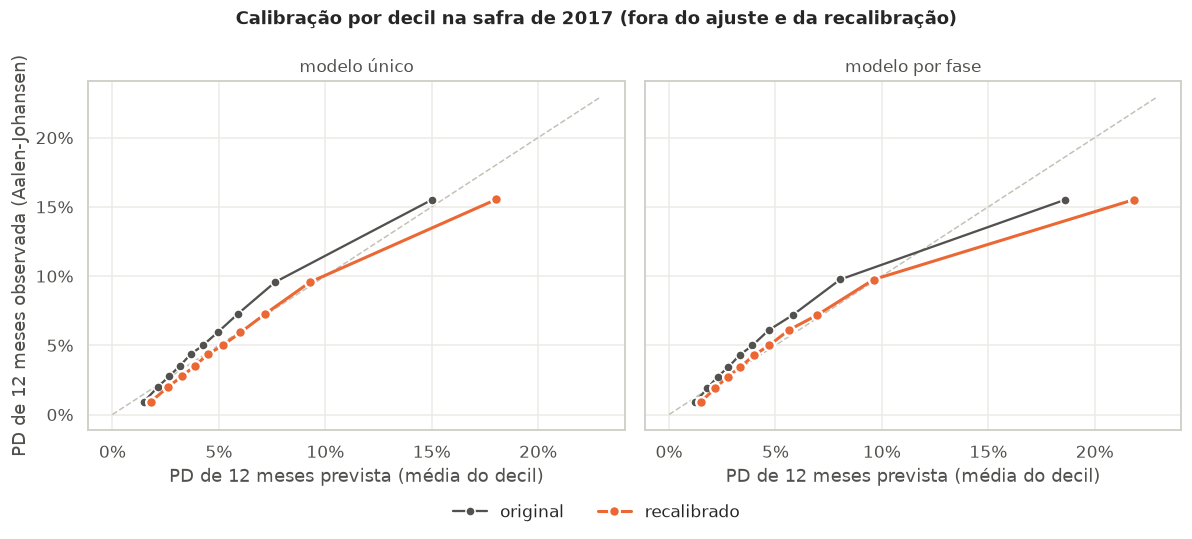

,erro médio absoluto por decil (p.p.),PD média prevista,PD média observada,razão observada/prevista no decil 10
modelo único recalibrado,0.5637,0.0617,0.0568,0.8616
modelo por fase recalibrado,0.8672,0.0625,0.0568,0.7106
modelo único (original),0.7356,0.0509,0.0568,1.0331
modelo por fase (original),1.1133,0.0525,0.0568,0.8334


In [8]:
mask_2017 = (test["vintage"] == 2017).to_numpy()


def decile_calibration(p12):
    deciles = pd.qcut(p12[mask_2017], 10, labels=False)
    rows = []
    for d in range(10):
        m = np.zeros(len(test), dtype=bool)
        m[np.flatnonzero(mask_2017)[deciles == d]] = True
        rows.append({"decil": d + 1, "prevista": p12[m].mean(), "observada": observed_cif(m, 12)})
    return pd.DataFrame(rows).set_index("decil")


deciles = {name: decile_calibration(p["pd_12m"].to_numpy()) for name, p in recalibrated.items()}
original = {name: decile_calibration(p["pd_12m"].to_numpy()) for name, p in preds.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
lim = 1.05 * max(t.max().max() for t in [*original.values(), *deciles.values()])
for ax, name in zip(axes, models):
    before, after_ = original[name], deciles[f"{name} recalibrado"]
    ax.plot([0, lim], [0, lim], color=LIGHT_GRAY, lw=1, ls="--")
    ax.plot(before["prevista"], before["observada"], "o-", color=GRAY, ms=6, lw=1.5, mec="white", label="original")
    ax.plot(after_["prevista"], after_["observada"], "o-", color=ORANGE, ms=7, mec="white", mew=1.5, label="recalibrado")
    ax.set_title(name, fontsize=11, fontweight="normal", color=GRAY)
    ax.set_xlabel("PD de 12 meses prevista (média do decil)")
    percent_axis(ax, "x")
    percent_axis(ax)
axes[0].set_ylabel("PD de 12 meses observada (Aalen-Johansen)")
fig.suptitle("Calibração por decil na safra de 2017 (fora do ajuste e da recalibração)", fontweight="bold", fontsize=12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.06), frameon=False)
fig.tight_layout()
savefig(fig, "calibration_deciles_2017")
plt.show()

calib_error = pd.DataFrame({
    name: {
        "erro médio absoluto por decil (p.p.)": 100 * (deciles[name]["prevista"] - deciles[name]["observada"]).abs().mean(),
        "PD média prevista": deciles[name]["prevista"].mean(),
        "PD média observada": deciles[name]["observada"].mean(),
        "razão observada/prevista no decil 10": deciles[name].loc[10, "observada"] / deciles[name].loc[10, "prevista"],
    }
    for name in deciles
} | {
    f"{name} (original)": {
        "erro médio absoluto por decil (p.p.)": 100 * (original[name]["prevista"] - original[name]["observada"]).abs().mean(),
        "PD média prevista": original[name]["prevista"].mean(),
        "PD média observada": original[name]["observada"].mean(),
        "razão observada/prevista no decil 10": original[name].loc[10, "observada"] / original[name].loc[10, "prevista"],
    }
    for name in original
}).T
calib_error

In [9]:
deciles["modelo único recalibrado"].join(deciles["modelo por fase recalibrado"], lsuffix=" (único)", rsuffix=" (por fase)")

,prevista (único),observada (único),prevista (por fase),observada (por fase)
decil,,,,
1,0.0180,0.0092,0.0149,0.0092
2,0.0260,0.0197,0.0217,0.0189
3,0.0325,0.0275,0.0275,0.0274
4,0.0386,0.0351,0.0335,0.0341
5,0.0449,0.0436,0.0398,0.0429
6,0.0518,0.0500,0.0470,0.0499
7,0.0602,0.0593,0.0562,0.0609
8,0.0718,0.0728,0.0698,0.0720
9,0.0929,0.0957,0.0961,0.0975


## Conclusões

1. **O modelo ordena melhor que o grade da LendingClub.** O C-index fora do tempo é de 0,698 (modelo único) e 0,699 (modelo por fase), contra 0,682 do grade da plataforma, usando só informação disponível na concessão. A diferença entre os dois modelos é mínima.
2. **Sem recalibração, o modelo subestima as safras novas.** Ele prevê 4,5% de default em 12 meses para os contratos de 36 meses da safra de 2016, contra 5,7% observados (−20%). O erro é maior nos horizontes curtos: em 6 meses, a safra de 2018 fica 26% (36m) e 33% (60m) abaixo do observado. É o mesmo movimento do notebook 03: as safras novas quebram mais, e mais cedo.
3. **Recalibrar o nível com a safra mais recente ajuda, mas não resolve tudo.** O multiplicador estimado na safra de 2016 (1,23 no modelo único) transforma uma subestimação de 10% numa **superestimação de 9%** na safra de 2017, cuja PD média é 6,2% prevista contra 5,7% observada. O erro médio por decil cai de 0,74 para 0,56 p.p. Por contrato o efeito é misto: melhora nos de 36 meses (de −12% para +7%) e piora nos de 60 meses (de −8% para +11%). O nível do risco muda de safra para safra, então qualquer recalibração com uma safra transfere o nível *daquela* safra.
4. **Para provisão, errar para cima é o lado prudente.** Depois da recalibração, o viés na safra de 2017 é conservador, e o mês 6 da safra de 2018 ainda fica abaixo do observado (−10% e −18%). Em produção, isso pede **recalibração periódica** (por exemplo, trimestral, com a safra mais recente) e monitoramento da razão observada/prevista.
5. **Os extremos têm desvios previsíveis.** O decil de menor risco tem PD prevista de 1,8% contra 0,9% observada, o mesmo efeito da forma funcional dos juros vista no notebook 04 (juros muito baixos são mais seguros do que a reta prevê). O decil de maior risco também é superestimado depois da recalibração.

**Modelo escolhido para a PCLD: modelo único recalibrado.** Ele tem a melhor calibração por decil (0,56 p.p. contra 0,87 do modelo por fase), e a calibração importa mais que a ordenação para provisionar. É também o mais simples de manter e explicar. A vantagem do modelo por fase em ordenação (+0,002 no C-index) não compensa.

In [10]:
final = "modelo único"
update_metrics("validation", {
    "test_vintages": [2016, 2018],
    "test_loans": int(len(test)),
    "c_index_test": {k: round(float(v), 4) for k, v in c_index.items()},
    "default_scale": {k: round(float(v), 4) for k, v in scales.items()},
    "recalibration_target_pd12_2016": round(float(target), 4),
    "by_vintage_error": {f"{s}_{p}m_{h}m": {k: round(float(v), 4) for k, v in row.items()}
                         for (s, p, h), row in check[[c for c in check.columns if c.startswith("erro")]].iterrows()},
    "by_vintage_error_original": {f"{s}_{p}m_{h}m": {k: round(float(v), 4) for k, v in row.items()}
                                  for (s, p, h), row in by_vintage[[f"erro {n}" for n in models]].iterrows()},
    "decile_mae_pp_2017": calib_error["erro médio absoluto por decil (p.p.)"].round(3).to_dict(),
    "pd12_2017_pred_vs_obs": {k: [round(float(r["PD média prevista"]), 4), round(float(r["PD média observada"]), 4)]
                              for k, r in calib_error.iterrows()},
    "chosen_model": f"{final} recalibrado",
})

{'data': {'raw_loans': 2260668,
  'loans': 2064692,
  'snapshot': '2019-03',
  'observation_end': '2018-11',
  'funnel': [{'etapa': 'base bruta', 'contratos': 2260668, 'removidos': 0},
   {'etapa': 'dentro da política de crédito',
    'contratos': 2257919,
    'removidos': 2749},
   {'etapa': 'pedido individual', 'contratos': 2137209, 'removidos': 120710},
   {'etapa': 'moradia própria, financiada ou aluguel',
    'contratos': 2136024,
    'removidos': 1185},
   {'etapa': 'renda anual positiva', 'contratos': 2136024, 'removidos': 0},
   {'etapa': 'emitido antes do fim da observação',
    'contratos': 2064692,
    'removidos': 71332}],
  'event_share': {'censurado': 0.5047,
   'pré-pagamento': 0.3715,
   'default': 0.1239},
  'term_36_share': 0.72},
 'kaplan_meier': {'term_36': {'cif_default_12m': 0.0487,
   'cif_default_term': 0.1444,
   'naive_km_default_term': 0.206,
   'cif_prepay_term': 0.5623},
  'term_60': {'cif_default_12m': 0.07,
   'cif_default_term': 0.27,
   'naive_km_defaul